# A one-window audit for adaptive intrusion detection

**Question.** How much of the recall gain from immediate updates can we preserve when a detector must produce evidence against a user-supplied false-positive cap?

A challenger can train and be audited as soon as labels arrive from the same completed window. Independent review samples keep fitting, cutoff calibration and audit separate. The audit checks false positives and missed attacks together. In a locked replay of two additional CSE-CIC-IDS2018 capture days, fast replacement at a 1% cap reached **74.51% recall**, compared with **66.94%** for the delayed audit and **85.65%** for immediate replacement. The frozen model reached **43.49%**. The fast gate stayed within budget in **18 of 21** windows per run, including the first window after each of its **13** approvals across the three review seeds.

**Scope of the confidence statement.** The bound covers the eligible rows of the completed source window for one fixed candidate pair, at its decision-time thresholds. The later-window numbers are replay measurements. They depend on traffic drift and may exceed the cap. Labels were simulated as complete and correct after one window.

## Set the operating budget

The false-alarm budget is an FPR cap among benign flows. A 1% cap allows one false-positive flow per 100 benign flows on average in the population being checked. Analyst capacity also depends on traffic volume and alert aggregation. The recall floor is separate because an extremely high threshold can satisfy an FPR cap while missing most attacks. Replacement normally requires a positive lower bound on net attacks found. It can also repair a demonstrably over-budget incumbent if the lower bound on recall change is at least −5 percentage points. The 20% floor and the five-point repair tolerance are research settings.

The saved results below use the recorded settings. Set `RUN_FOCUSED_REPLAY` to `True` and choose a dataset to run a new comparison at the configured cap. The optional replay needs the pinned public flow files and can take several minutes.

In [1]:
from pathlib import Path

FALSE_ALARM_CAP_PERCENT = 1.0
MINIMUM_SOURCE_RECALL_PERCENT = 20.0
AUDIT_REVIEWS_PER_WINDOW = 2048
REPLAY_DATASET = 'CSE-CIC-IDS2018 held-out days'
REPLAY_SEEDS = (42, 43, 44)
RUN_FOCUSED_REPLAY = False
DATA_DIR = Path('one_window_audit_data')

if not 0 < FALSE_ALARM_CAP_PERCENT < 100:
    raise ValueError('Set the false-positive cap as a percentage between 0 and 100.')
if not 0 <= MINIMUM_SOURCE_RECALL_PERCENT <= 100:
    raise ValueError('Set the recall floor as a percentage between 0 and 100.')
if not isinstance(AUDIT_REVIEWS_PER_WINDOW, int) or AUDIT_REVIEWS_PER_WINDOW < 2:
    raise ValueError('Use an integer budget of at least two audit labels per window.')

In [2]:
from base64 import b64decode
from gzip import decompress
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SAVED = json.loads(decompress(b64decode(
    "..."
)))
LOCK = SAVED['protocol']
HELD_OUT = SAVED['new_locked']['runs']

## What changes when the audit runs in parallel?

1. At the end of window *t*, reserve 2,048 training and 512 threshold-calibration labels. Draw the audit from the remaining rows before any of these labels arrive. Uniform sampling is the simplest design. The other designs can use alerts or score ranks from models already available in window *t*.
2. At the beginning of window *t+1*, fit the challenger using matured training labels and set the cutoffs using separate benign calibration labels. Score the eligible source rows and fix the two alert masks before opening the audit labels. A delayed shadow audit instead waits for traffic on which the completed challenger can already be scored, then requests the paired labels.
3. Estimate the false-positive and recall bounds on the eligible source rows. Accept a replacement only when its FPR upper bound is at most the cap and the recall rules pass. The overlay uses the union of the frozen detector and challenger alerts. It can protect incumbent detections from removal and inherits all incumbent false positives in the same window.

The base model is a 320-tree histogram gradient booster trained on historical flow behavior. The local model adds 40 trees on CSE-CIC-IDS2018 and 80 on CTU-13. Its training includes a historical anchor and recent verified flows, with extra weight on the base detector's mistakes. All policies share the same base and local model versions within a run. Unless a policy calibrates its cutoff in the audit, its threshold targets 10% of the requested FPR cap on the latest adequate verified benign set, with historical fallback. The frozen policy freezes the score model and still updates this cutoff. A replacement persists until another is accepted. An overlay expires after the next window.

**Finite-population check.** For a fixed alert pattern, sample counts in every label-free subpopulation are hypergeometric conditional on the realized number reviewed there. Invert their tails and split a 5% error allowance across the count bounds. A lower bound on alerted attacks gives an upper bound $FP^U$ on benign alerts. Combine it with a lower bound $TN^L$ on unalerted benign rows to get $FPR^U=FP^U/(FP^U+TN^L)$. Use the corresponding attack counts for recall and for the net change in detected attacks. This construction needs independent randomized review within strata, a fixed pair conditional on past evidence and separated training and calibration, and reliable labels. The 95% level is per audit. The independent calibrated overlay instead selects a cutoff by a conservative benign order statistic, and checks only source FPR.

## Locked replay on additional CSE-CIC-IDS2018 capture days

February 14 supplies historical training and February 15 supplies historical calibration. The protocol was frozen before scoring February 21 and March 2. These two days contribute 2,097,150 eligible flows across 21 blocks of roughly 100,000 flows ordered by estimated completion. February 16 and 20 were used earlier for development. This split tests transfer across capture days within one benchmark. The three review seeds vary the requests and the resulting local models on the same traffic.

The scout-stratified overlay was the **preselected primary** after the development replay. Uniform fast replacement was a **prelocked secondary**. The table averages flow-level rates across review seeds. “Approved then over” counts only the first live block after a promotion or addition. Audit labels are separate from training and calibration labels.

In [3]:
PRIMARY_COMPARISONS = [
    ('Frozen score, rolling cutoff', 'frozen', None, 0),
    ('Delayed shadow replacement', 'shadow replacement', None, 2048),
    ('Fast uniform replacement (secondary)', 'fast replacement', 'uniform', 2048),
    ('Fast scout overlay (primary)', 'fast overlay', 'scout alerts', 2048),
    ('Fast calibrated overlay', 'calibrated overlay', 'uniform', 2048),
    ('Immediate replacement', 'immediate replacement', None, 0),
]


def select(runs, policy, design, budget):
    return sorted((r for r in runs if (r['policy'], r['design'], r['audit_budget'])
                   == (policy, design, budget)), key=lambda r: r['seed'])


def mean_rate(runs, key):
    return float(np.mean([r[key] for r in runs])) * 100


def comparison_row(label, runs):
    return {
        'Policy': label,
        'Recall (%)': round(mean_rate(runs, 'recall'), 3),
        'FPR (%)': round(mean_rate(runs, 'fpr'), 3),
        'Within cap by seed': ', '.join(f"{r['windows_under_cap']}/{r['windows_with_benign']}" for r in runs),
        'Approvals': sum(r['approvals'] for r in runs),
        'Approved then over': sum(r['approvals_over_cap_next'] for r in runs),
        'Mean audit labels per run': round(np.mean([r['audit_labels'] for r in runs])),
    }


heldout_groups = {label: select(HELD_OUT, policy, design, budget)
                  for label, policy, design, budget in PRIMARY_COMPARISONS}
heldout_table = pd.DataFrame([comparison_row(label, runs) for label, runs in heldout_groups.items()])
display(heldout_table.set_index('Policy'))

frozen, shadow, fast, primary, calibrated, immediate = heldout_groups.values()
fast_recall = mean_rate(fast, 'recall')
retained = (fast_recall - mean_rate(frozen, 'recall')) / (mean_rate(immediate, 'recall') - mean_rate(frozen, 'recall'))
print(f'Fast replacement gains {fast_recall - mean_rate(shadow, "recall"):.2f} recall points over shadow '
      f'and retains {retained:.1%} of the incremental recall from immediate updates.')

family_rows = []
for label, runs in list(heldout_groups.items()):
    if 'families' not in runs[0]:
        continue
    for family, counts in sorted(runs[0]['families'].items()):
        family_rows.append({'Policy': label, 'Attack family': family, 'Attack flows': counts['attacks'],
                            'Recall (%)': round(100 * np.mean([r['families'][family]['detected']
                                                             for r in runs]) / counts['attacks'], 2)})
family_results = pd.DataFrame(family_rows)
display(family_results.pivot(index=['Attack family', 'Attack flows'], columns='Policy', values='Recall (%)'))

,Recall (%),FPR (%),Within cap by seed,Approvals,Approved then over,Mean audit labels per run
Policy,,,,,,
"Frozen score, rolling cutoff",43.494,0.450,"17/21, 18/21, 17/21",0,0,0
Delayed shadow replacement,66.936,0.508,"18/21, 18/21, 18/21",12,0,26624
Fast uniform replacement (secondary),74.507,0.482,"18/21, 18/21, 18/21",13,0,40960
Fast scout overlay (primary),66.358,0.597,"17/21, 18/21, 17/21",33,3,40960
Fast calibrated overlay,75.240,0.786,"16/21, 18/21, 17/21",46,5,40960
Immediate replacement,85.649,0.574,"18/21, 18/21, 18/21",0,0,0


,Policy,Delayed shadow replacement,Fast scout overlay (primary),Fast uniform replacement (secondary),"Frozen score, rolling cutoff",Immediate replacement
Attack family,Attack flows,,,,,
Bot,286191,74.80,64.23,87.66,44.80,91.23
DDOS attack-HOIC,686012,63.57,67.16,68.96,43.06,83.28
DDOS attack-LOIC-UDP,1730,100.00,100.00,100.00,0.00,100.00


Fast replacement gains 7.57 recall points over shadow and retains 73.6% of the incremental recall from immediate updates.


Measured FPR (%)  Frozen FPR (%)
Policy                       Seed Live window                                  
Fast scout overlay (primary) 42   11                      6.970           4.903
                             43   11                      6.939           4.903
                             44   11                      6.922           4.903
Fast calibrated overlay      42   11                      6.970           4.903
                                  12                      1.164           1.063
                                  17                      1.331           0.279
                             43   11                      6.939           4.903
                             44   11                      6.922           4.903

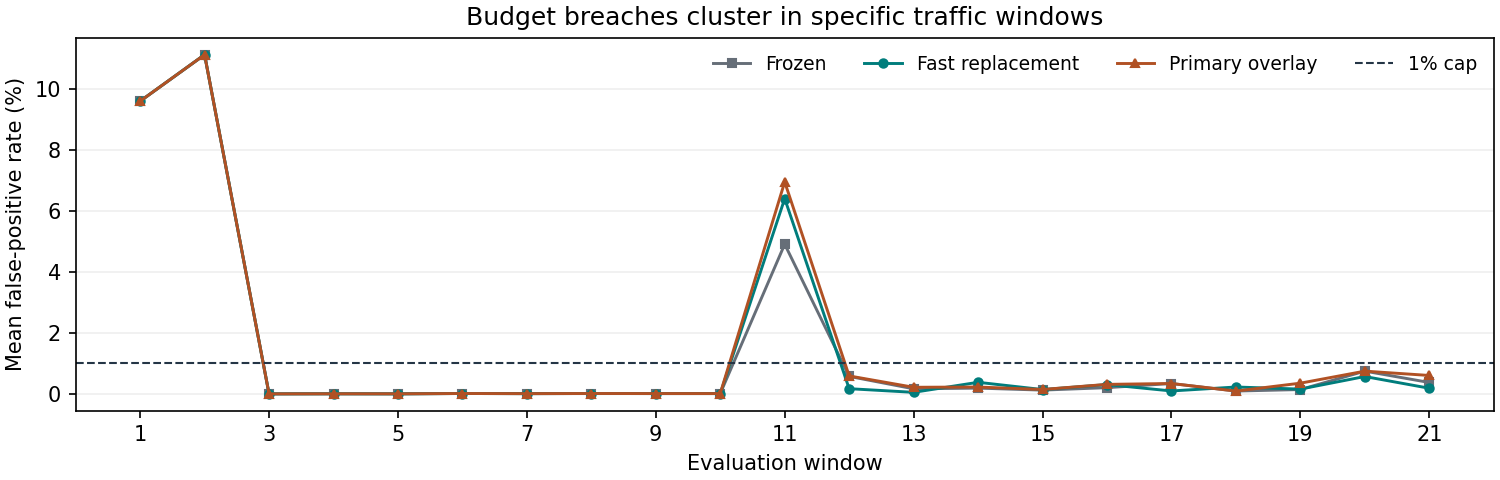

In [4]:
frozen_by_seed = {r['seed']: {w['window']: w['fpr'] for w in r['window_metrics']} for r in frozen}
breaches = []
for label, runs in heldout_groups.items():
    for run in runs:
        for audit in run['decisions']:
            if audit['approved'] and audit['actual_fpr'] > run['cap']:
                window = audit['live_window']
                breaches.append({'Policy': label, 'Seed': run['seed'], 'Live window': window,
                                 'Measured FPR (%)': round(100 * audit['actual_fpr'], 3),
                                 'Frozen FPR (%)': round(100 * frozen_by_seed[run['seed']][window], 3)})
display(pd.DataFrame(breaches).set_index(['Policy', 'Seed', 'Live window']))

fig, ax = plt.subplots(figsize=(10.0, 3.2), layout='constrained')
for label, runs, color, marker in [
    ('Frozen', frozen, '#666e78', 's'), ('Fast replacement', fast, '#007d7c', 'o'),
    ('Primary overlay', primary, '#b15124', '^'),
]:
    window_numbers = [w['window'] for w in runs[0]['window_metrics']]
    fpr_by_window = [[w['fpr'] * 100 if w['fpr'] is not None else np.nan
                      for w in r['window_metrics']] for r in runs]
    ax.plot(window_numbers, np.nanmean(fpr_by_window, axis=0), color=color, marker=marker,
            markersize=4, linewidth=1.4, label=label)
ax.axhline(1, color='#243546', linestyle='--', linewidth=1, label='1% cap')
ax.set(xlabel='Evaluation window', ylabel='Mean false-positive rate (%)', title='Budget breaches cluster in specific traffic windows')
ax.set_xticks(range(1, 22, 2))
ax.legend(frameon=False, ncols=4, fontsize=9, loc='upper right')
ax.grid(axis='y', alpha=.20)
display(fig)
plt.close(fig)

The primary overlay achieved 66.36% recall and exceeded the cap immediately after three approvals. All three were in window 11, where the frozen detector was already at 4.90%. The overlay raised FPR to roughly 6.9%. The calibrated overlay had one approval whose complete source block exceeded the cap, and five whose first live block exceeded the cap. The fast and delayed replacement policies were over budget in windows 1, 2 and 11 for every seed. None of their first windows after an approval exceeded the cap. Repeating a per-window audit would require an explicit stream-level error policy to make a joint confidence claim.

## Where review spending flattened out

On the earlier sampled CSE-CIC-IDS2018 replay, the scout overlay at 2,048 audits reached 92.07% recall and 0.264% FPR in the development run. All 12 windows were within budget, and doubling the audit budget left its decisions unchanged. The primary overlay had lower recall and more breaches on the two additional days. CTU-13 gave a different bottleneck. At 2,048 audits a replacement could look feasible on the completed block and still lack enough verified benign labels to certify its FPR. In one such block, a uniform review found just 127 benign flows among 2,048 draws. Complete source FPR was 0.075% and the audit upper bound was 4.167%. The CTU-13 replay includes explicitly labeled Normal and Botnet rows. Background rows of unknown status are excluded.

The CTU-13 ladder below compares the original count bounds with a class-conditional FPR bound applied to the same uniform samples. The latter uses an exact benign-count lower bound and a conservative correction to a binomial upper bound. At **5,120** audits per source window both methods reached **58.39% mean recall**, **0.728% FPR** and **9 of 10** windows within budget for each seed. The 8,192-label mean was **58.48%** recall. The middle step can dip because changing one approval also changes the incumbent for later audits. This is a plateau over the tested replay settings. There are also 2,048 training and 512 calibration requests per source window.

Mean recall (%)  Min recall (%)  Max recall (%)  Mean FPR (%)  Approvals  Approved then over
FPR bound         Audits per window                                                                                              
partition counts  2048                        30.341          30.057          30.677         0.791          0                   0
                  4096                        49.850          45.144          59.162         0.729         10                   0
                  5120                        58.387          57.948          59.162         0.728         12                   0
                  6144                        58.387          57.948          59.162         0.728         12                   0
                  7168                        54.118          46.357          58.051         0.728         11                   0
                  8192                        58.477          57.948          59.162         0.729         13                   0
class conditional 2048                        33.692          33.242          34.467         0.729          4                   0
                  4096                        49.850          45.144          59.162         0.729         10                   0
                  5120                        58.387          57.948          59.162         0.728         12                   0
                  6144                        58.387          57.948          59.162         0.728         12                   0
                  7168                        58.387          57.948          59.162         0.728         12                   0
                  8192                        58.477          57.948          59.162         0.729         13                   0

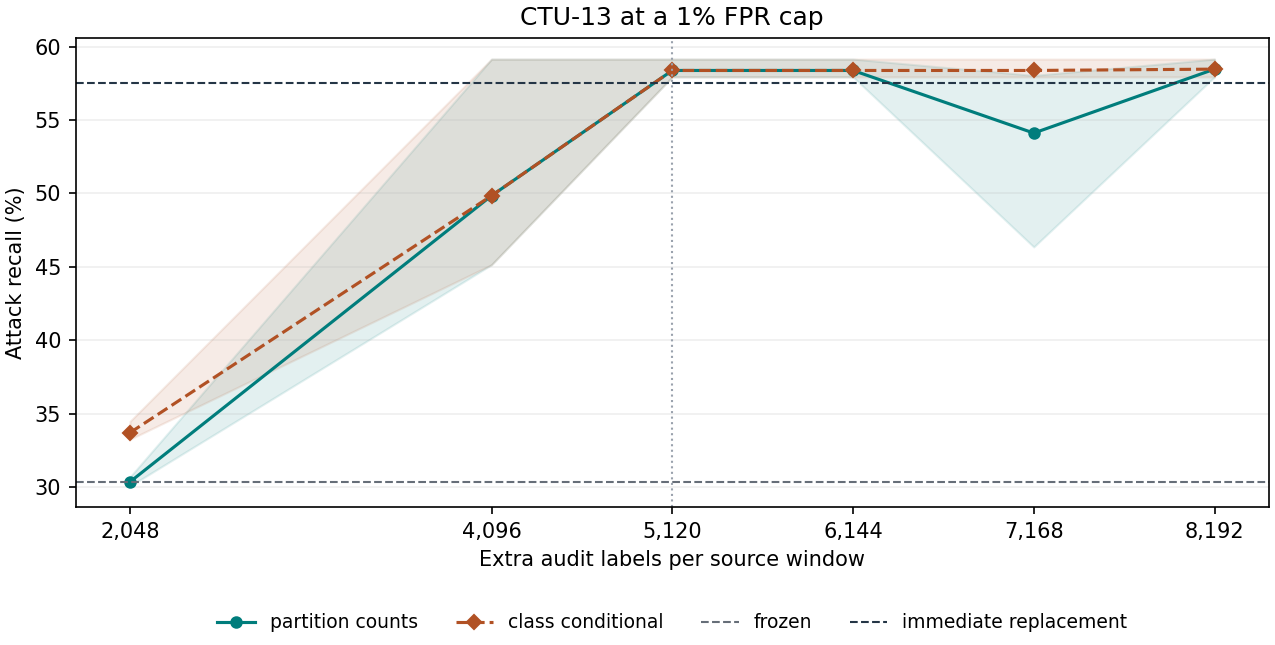

In [5]:
ctu_dev = SAVED['ctu_dev']['runs']
ctu_power = SAVED['ctu_power']['runs']
ctu_efficiency = SAVED['ctu_efficiency']
ctu_controls = [r for r in ctu_dev + ctu_efficiency if r['policy'] in ('frozen', 'immediate replacement')]
ctu_curve = [r for r in ctu_efficiency if 'risk_method' in r]
for rows, budget in [(ctu_dev, 2048), (ctu_dev, 4096), (ctu_power, 8192)]:
    ctu_curve.extend(dict(r, risk_method='partition counts')
                     for r in select(rows, 'fast replacement', 'uniform', budget))
assert len(ctu_curve) == 36

ladder_rows = []
for method in ('partition counts', 'class conditional'):
    for budget in (2048, 4096, 5120, 6144, 7168, 8192):
        runs = [r for r in ctu_curve if r['risk_method'] == method and r['audit_budget'] == budget]
        assert len(runs) == 3
        ladder_rows.append({'FPR bound': method, 'Audits per window': budget,
                            'Mean recall (%)': mean_rate(runs, 'recall'),
                            'Min recall (%)': min(r['recall'] * 100 for r in runs),
                            'Max recall (%)': max(r['recall'] * 100 for r in runs),
                            'Mean FPR (%)': mean_rate(runs, 'fpr'),
                            'Approvals': sum(r['approvals'] for r in runs),
                            'Approved then over': sum(r['approvals_over_cap_next'] for r in runs)})
ladder = pd.DataFrame(ladder_rows)
display(ladder.round(3).set_index(['FPR bound', 'Audits per window']))

fig, ax = plt.subplots(figsize=(8.5, 4.3), layout='constrained')
styles = [('#007d7c', 'o', '-'), ('#b15124', 'D', '--')]
for (method, runs), (color, marker, line) in zip(ladder.groupby('FPR bound', sort=False), styles):
    ax.plot(runs['Audits per window'], runs['Mean recall (%)'], marker=marker, color=color,
            linestyle=line, markersize=5, label=method)
    ax.fill_between(runs['Audits per window'], runs['Min recall (%)'], runs['Max recall (%)'], color=color, alpha=.11)
for policy, color in [('frozen', '#666e78'), ('immediate replacement', '#243546')]:
    rate = mean_rate([r for r in ctu_controls if r['policy'] == policy], 'recall')
    ax.axhline(rate, color=color, linestyle='--', linewidth=1, label=policy)
ax.axvline(5120, color='#9aa2ad', linestyle=':', linewidth=1)
ax.set(xlabel='Extra audit labels per source window', ylabel='Attack recall (%)',
       title='CTU-13 at a 1% FPR cap')
ticks = sorted(ladder['Audits per window'].unique())
ax.set_xticks(ticks, [f'{n:,}' for n in ticks])
ax.grid(axis='y', alpha=.20)
ax.legend(frameon=False, ncols=4, fontsize=9, loc='upper center', bbox_to_anchor=(.5, -.19))
display(fig)
plt.close(fig)

## Sensitivity to the requested cap

This follow-up uses only development traffic and fixes audit spending at 5,120 per CTU-13 source window and 2,048 per CSE-CIC-IDS2018 source window. The same audit rows and model versions are reused across caps within each seed. Changing the cap also changes the operating threshold because the headroom multiplier is fixed. Each row reports the realized FPR, attacks caught and attacks missed. The target alone cannot establish whether the detector has enough information to operate there.

CTU-13 fast replacement approved three candidates at 0.5% and caught 31.22% of attacks. At 1%, it approved 12 and caught 58.39%. Relaxing the cap to 2% increased recall to 59.97% while mean FPR more than doubled from 0.728% to 1.621%. On the sampled CSE development days, recall changed less, from 89.85% at 0.5% to 91.77% at 2%. The volume and composition of verified benign evidence affect how much a stricter cap costs in missed attacks.

In [6]:
cap_rows = []
for key in ('ctu', 'cic'):
    runs = SAVED[f'{key}_cap_sweep']
    for cap in (.005, .01, .02):
        for policy in ('frozen', 'immediate replacement', 'fast replacement'):
            group = [r for r in runs if r['policy'] == policy and r['cap'] == cap]
            row = comparison_row(policy, group)
            row.update({'Development stream': group[0]['dataset'], 'Requested cap (%)': cap * 100,
                        'Mean missed attack flows': round(np.mean([r['missed'] for r in group]))})
            cap_rows.append(row)
cap_table = pd.DataFrame(cap_rows)
display(cap_table.set_index(['Development stream', 'Requested cap (%)', 'Policy']))

Recall (%)  FPR (%)   Within cap by seed  Approvals  Approved then over  Mean audit labels per run  Mean missed attack flows
Development stream Requested cap (%) Policy                                                                                                                                             
CTU-13             0.5               frozen                     28.864    0.511     7/10, 7/10, 7/10          0                   0                          0                    222293
                                     immediate replacement      55.914    0.498     9/10, 9/10, 8/10          0                   0                          0                    137764
                                     fast replacement           31.221    0.468     9/10, 9/10, 7/10          3                   0                      46080                    214929
                   1.0               frozen                     30.341    0.791     9/10, 9/10, 9/10          0                   0                          0                    217678
                                     immediate replacement      57.539    0.780     9/10, 9/10, 9/10          0                   0                          0                    132687
                                     fast replacement           58.387    0.728     9/10, 9/10, 9/10         12                   0                      46080                    130038
                   2.0               frozen                     31.711    1.633     9/10, 9/10, 9/10          0                   0                          0                    213396
                                     immediate replacement      59.622    1.620     9/10, 9/10, 9/10          0                   0                          0                    126178
                                     fast replacement           59.971    1.621     9/10, 9/10, 9/10         15                   0                      46080                    125086
CSE-CIC-IDS2018    0.5               frozen                     47.194    0.202   11/12, 9/12, 11/12          0                   0                          0                     77698
                                     immediate replacement      91.144    0.253    9/12, 9/12, 11/12          0                   0                          0                     13031
                                     fast replacement           89.849    0.253   9/12, 10/12, 10/12          6                   0                      22528                     14936
                   1.0               frozen                     47.792    0.202  12/12, 12/12, 12/12          0                   0                          0                     76818
                                     immediate replacement      91.742    0.253  12/12, 12/12, 12/12          0                   0                          0                     12151
                                     fast replacement           90.693    0.241  12/12, 12/12, 11/12          8                   0                      22528                     13694
                   2.0               frozen                     47.802    0.262  12/12, 12/12, 12/12          0                   0                          0                     76803
                                     immediate replacement      91.753    0.340  12/12, 12/12, 12/12          0                   0                          0                     12134
                                     fast replacement           91.772    0.379  12/12, 12/12, 12/12          9                   0                      22528                     12106

## Interpretation and literature

The empirical contribution is a test of *when* labels can be collected and *how much* independent review evidence an update needs. The comparison includes immediate deployment, audit after another block, audit using a reserved sample from the preceding block, and the alert-preserving overlay. The guarded fast policy retained useful recall on both streams at their tested review budgets. On the additional capture days, the primary overlay retained incumbent alerts but inherited its largest false-positive spike. The faster replacement gate improved recall over shadowing at the cost of more total audit requests, 40,960 versus 26,624 per CSE run on average. Neither label-budget plateau establishes an optimal budget for another deployment.

- Tong, Feng and Li formalize recall maximization under a type-I error constraint and develop benign-score order-statistic calibration. That separates the operator's FPR cap from the sampling confidence in the cutoff. [Science Advances, 2018](https://doi.org/10.1126/sciadv.aao1659)
- Fernández-Barrios and colleagues show that conclusions about NIDS promotion depend on challenger construction and comparable evidence. This replay holds those model versions fixed within a run and compares the latency and cost of collecting promotion evidence. [arXiv preprint, 2026](https://arxiv.org/abs/2609.04388)
- Waudby-Smith and Ramdas develop confidence sequences for sampling without replacement. The fixed-size audits here use one-time hypergeometric inversions. Sequential verification with variable label turnaround is a follow-on to test with an anytime-valid design. [NeurIPS, 2020](https://proceedings.neurips.cc/paper/2020/hash/e96c7de8f6390b1e6c71556e4e0a4959-Abstract.html)
- Benchmark provenance and capture descriptions are available from the dataset providers. [CSE-CIC-IDS2018](https://registry.opendata.aws/cse-cic-ids2018/) · [CTU-13](https://www.stratosphereips.org/datasets-ctu13/)

The replays use flow counts and simulated labels. They do not estimate incident-level recall, reviewer error, actual turnaround, or performance at independent sites. An incident-weighted recall target and a verification budget measured in analyst time would test how the same gate behaves when missed attacks and reviews have unequal costs.

## Reproduce the replay

`SAVED` contains the locked protocol, input manifests with SHA-256 digests, feature names, every comparison run, every block's counts, and the per-audit decision log. The source below can reconstruct the comparison from public CSV and flow files. The tested runtime used Python 3.12, NumPy 2.3.5, pandas 2.2.3, SciPy 1.17.0, scikit-learn 1.8.0, Matplotlib 3.10.8 and threadpoolctl. For CTU-13, place previously verified `42.binetflow` through `54.binetflow` in `DATA_DIR / 'ctu'` if the public mirror is unavailable. For CSE, the raw CSV loader downloads the pinned files if they are absent. Default execution needs no network access.

In [7]:
from dataclasses import dataclass
from functools import lru_cache
from scipy.special import logit
from scipy.stats import beta, hypergeom
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from threadpoolctl import threadpool_limits

In [8]:
from concurrent.futures import ThreadPoolExecutor


from hashlib import file_digest


from pathlib import Path


from shutil import copyfileobj


from time import sleep


from urllib.request import urlopen


from uuid import uuid4


CTU_FILES = {
    '42': 'capture20110810.binetflow.2format',
    '43': 'capture20110811.binetflow.2format',
    '44': 'capture20110812.binetflow.2format',
    '45': 'capture20110815.binetflow.2format',
    '46': 'capture20110815-2.binetflow.2format',
    '47': 'capture20110816.binetflow.2format',
    '48': 'capture20110816-2.binetflow.2format',
    '49': 'capture20110816-3.binetflow.2format',
    '50': 'capture20110817.binetflow.2format',
    '51': 'capture20110818.binetflow.2format',
    '52': 'capture20110818-2.binetflow.2format',
    '53': 'capture20110819.binetflow.2format',
    '54': 'capture20110815-3.binetflow.2format',
}


CTU_BASE = 'https://mcfp.felk.cvut.cz/publicDatasets'


def fetch_capture(item, directory):
    key, filename = item
    path = directory / f'{key}.binetflow'
    if path.is_file():
        return path
    url = f'{CTU_BASE}/CTU-Malware-Capture-Botnet-{key}/{filename}'
    part = path.with_suffix(f'.{uuid4().hex}.part')
    for attempt in range(3):
        try:
            with urlopen(url, timeout=85) as response, part.open('wb') as out:
                expected = response.headers.get('Content-Length')
                copyfileobj(response, out, length=4 * 1024**2)
            with part.open('rb') as source:
                header = source.readline()
            if b'LastTime' not in header or b'Label' not in header:
                raise ValueError(f'Unexpected CTU-13 file header for {key}.')
            if expected and int(expected) != part.stat().st_size:
                raise IOError(f'Incomplete capture {key}.')
            part.replace(path)
            print(f'CTU {key}: {path.stat().st_size / 1e6:.1f} MB', flush=True)
            return path
        except (OSError, ValueError) as error:
            part.unlink(missing_ok=True)
            if attempt == 2:
                raise RuntimeError(f'Failed to fetch CTU capture {key}.') from error
            print(f'Retrying capture {key} after {type(error).__name__}', flush=True)
            sleep(3 * (attempt + 1))


def fetch_ctu(directory, workers=6):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    with ThreadPoolExecutor(max_workers=workers) as pool:
        return list(pool.map(lambda item: fetch_capture(item, directory), CTU_FILES.items()))

from concurrent.futures import ThreadPoolExecutor


from hashlib import file_digest


from pathlib import Path


from shutil import copyfileobj


from urllib.parse import quote


from urllib.request import urlopen


from uuid import uuid4


CIC18_NAMES = {
    '14': 'Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv',
    '15': 'Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv',
    '16': 'Friday-16-02-2018_TrafficForML_CICFlowMeter.csv',
    '20': 'Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv',
}


CIC18_BASE = 'https://cse-cic-ids2018.s3.amazonaws.com'


CIC18_SHA256 = {
    '14': 'acff8bc61376ee031d80878ee6099e0b1a87a1bd711d8068298421418c9f8147',
    '15': 'fa2947a8256d81ee9103ae16139d62d0e17aa23e696ee80d9e76fb51c01c9c4b',
    '16': '1a4919faa0c49c7af97230b0c2d076eba23ee6dd81103a3801d51ac316355d8b',
    '20': '7287a4d7740a1dddbf330ceb2beb6a4889d33ba63674558a68b5eb50d16711df',
}


def download_cic_day(day, directory):
    target = directory / CIC18_NAMES[day]
    if not target.is_file():
        temporary = target.with_suffix(f'.{uuid4().hex}.part')
        path = f'Processed Traffic Data for ML Algorithms/{CIC18_NAMES[day]}'
        url = f'{CIC18_BASE}/{quote(path)}'
        try:
            with urlopen(url, timeout=120) as response, temporary.open('wb') as out:
                expected = response.headers.get('Content-Length')
                copyfileobj(response, out, length=4 * 1024**2)
            if expected and int(expected) != temporary.stat().st_size:
                raise OSError(f'Incomplete file for Feb {day}.')
            with temporary.open('rb') as f:
                header = f.readline()
            if b'Timestamp' not in header or b'Label' not in header:
                raise ValueError(f'Unexpected CICFlowMeter CSV for Feb {day}.')
            temporary.replace(target)
        finally:
            temporary.unlink(missing_ok=True)
    with target.open('rb') as f:
        sha = file_digest(f, 'sha256').hexdigest()
    if sha != CIC18_SHA256[day]:
        raise ValueError(f'CSE-CIC-IDS2018 Feb {day} differs from the pinned release.')
    print(f'CSE-CIC-IDS2018 Feb {day} file {target.stat().st_size:,} bytes SHA-256 {sha}', flush=True)
    return target, sha


def fetch_cic18(directory, days=tuple(CIC18_NAMES)):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    with ThreadPoolExecutor(max_workers=4) as pool:
        return dict(zip(days, pool.map(lambda day: download_cic_day(day, directory), days)))

CTU_PARTS = {'train': ('42', '43', '44'), 'cal': ('45', '46', '54'),
             'stream': ('47', '48', '49', '50', '51', '52', '53')}


CTU_SHA256 = {'42': 'e9d2d3c5adc6ea61e9149fdb12ad49a3aa84d296da9bacd0da07e95a05d43912',
 '43': '1236bb60d922c72e0b002792ce92ab3156dbbdab0765080a16ce86484fd27a8c',
 '44': '3b97733f26890631bbf36a0fb8f92395d6fbb21e7aa5e3e42a97ff5540e389d7',
 '45': 'a8c9c83720ef70e4538bbf42ccee065e580b990215e9bee58866666cbfaf8d83',
 '46': 'f6fd1d0fd8e13cbd54a2e8e5235dc6dce0d2beee58b78ce2c176646cf00c3807',
 '47': '8110530e87e80d996b7e922b04ceec72e7f8589af91a28662a6a767c90fb5163',
 '48': '8cc97aaea02190817675ba55eb924eeb7958986790f09f46650d8a360f5723cb',
 '49': 'f54d2c91da93faf6395777c40cd9b974f52a6e62db470b05583ca41ab04c0147',
 '50': '306ce0e7ec541012017a879223f8c3b970132767d6cddca60b2f7c465d3f3d9c',
 '51': '786f2a7750074cd3de507bb6ab7431c98e8207529591ae4b8c30ccc67aa8219d',
 '52': 'a78e3a297fd07fe4b9a076a93c94b06732679947d96179ebe662cec4339374fc',
 '53': 'd669dbef76f4f45d9e69aab1be1c623d7327c1c765657c60e587df4a36913e21',
 '54': '10448d328d0b59a60d2ba4c06c26a947bfe6e43d0bdddbcf9b75235d8fb4153a'}


CTU_COUNTS = {'train': 245118, 'cal': 105370, 'stream': 450644}


def binary_windows(time, size):
    """Take chronological windows with a minimum size, retaining completion-time ties."""
    time = np.asarray(time)
    if not len(time) or np.any(time[1:] < time[:-1]):
        raise ValueError('Completion times must be nonempty and sorted.')
    boundaries = []
    start = 0
    while start < len(time):
        end = min(start + size, len(time))
        if end < len(time):
            end = int(np.searchsorted(time, time[end - 1], side='right'))
        boundaries.append(slice(start, end))
        start = end
    return boundaries

@dataclass
class Bench:
    name: str
    x_train: np.ndarray
    y_train: np.ndarray
    x_cal: np.ndarray
    y_cal: np.ndarray
    windows: list
    truth: list
    families: list
    features: list
    dimensions: dict
    inventory: list
    manifests: list


FEATURE_GROUPS = ('basic', 'behavior', 'context')


CTU_BASIC = ('Dur', 'TotPkts', 'TotBytes', 'SrcBytes')


CTU_SHAPE = ('SrcPkts', 'DstPkts', 'DstBytes', 'SAppBytes', 'DAppBytes', 'TotAppByte',
             'TcpRtt', 'SynAck', 'AckDat', 'SrcWin', 'DstWin', 'Rate', 'SrcRate', 'DstRate')


CTU_CONTEXT = ('sTtl', 'dTtl', 'sHops', 'dHops', 'sTos', 'dTos')


CIC_BASIC = ('Flow Duration', 'Total Pkts', 'Total Bytes', 'TotLen Fwd Pkts')


CIC_SHAPE = (
    'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Bwd Pkts',
    'Fwd Pkt Len Min', 'Fwd Pkt Len Max', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std',
    'Bwd Pkt Len Min', 'Bwd Pkt Len Max', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std',
    'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Min', 'Flow IAT Max',
    'Fwd IAT Mean', 'Bwd IAT Mean', 'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt',
    'PSH Flag Cnt', 'ACK Flag Cnt', 'Init Fwd Win Byts', 'Init Bwd Win Byts',
    'Fwd Header Len', 'Bwd Header Len', 'Active Mean', 'Idle Mean',
)


PORT_GROUPS = ((20, 21), (22,), (25, 465, 587), (53,), (67, 68), (80, 8080, 8000),
               (110, 143, 993, 995), (123,), (135, 137, 138, 139, 445), (443,), (3389,))


def numeric_features(frame, columns):
    if not columns:
        return []
    values = frame[list(columns)].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=np.float32)
    valid = np.isfinite(values) & (values >= 0)
    return [np.log1p(np.where(valid, values, np.nan))]


def feature_maker(train, basic, behavior, context, proto, state=None, service=None, ports=()):
    # Vocabularies come from historical training only. Omitted categories map to all zeros.
    proto_vocab = train[proto].value_counts().head(8).index.to_list()
    state_vocab = train[state].value_counts().head(12).index.to_list() if state else []
    service_vocab = train[service].value_counts().head(8).index.to_list() if service else []
    basic_names = [*basic, *[f'{proto}={p}' for p in proto_vocab]]
    shape_names = [*behavior, *[f'{state}={p}' for p in state_vocab]]
    context_names = [*context, *[f'{service}={p}' for p in service_vocab]]
    for column in ports:
        context_names.extend([f'{column} in {group}' for group in PORT_GROUPS])
        context_names.append(f'{column}<1024')

    def encode(frame):
        features = numeric_features(frame, basic)
        features.extend([frame[proto].to_numpy() == p for p in proto_vocab])
        features.extend(numeric_features(frame, behavior))
        if state:
            features.extend([frame[state].to_numpy() == p for p in state_vocab])
        features.extend(numeric_features(frame, context))
        if service:
            features.extend([frame[service].to_numpy() == p for p in service_vocab])
        for column in ports:
            number = pd.to_numeric(frame[column], errors='coerce').to_numpy()
            features.extend([np.isin(number, group) for group in PORT_GROUPS])
            features.append((number >= 0) & (number < 1024))
        return np.column_stack(features).astype(np.float32, copy=False)

    dimensions = {'basic': len(basic_names), 'behavior': len(basic_names) + len(shape_names),
                  'context': len(basic_names) + len(shape_names) + len(context_names)}
    return encode, basic_names + shape_names + context_names, dimensions


def build_bench(name, train, cal, stream, size, config, manifests):
    for part in (train, cal, stream):
        if not part.completion.is_monotonic_increasing:
            raise ValueError('Replay input is not sorted by completion.')
    if not train.completion.max() < cal.completion.min() < stream.completion.min():
        raise ValueError('Unexpected chronology between partitions.')
    if not cal.completion.max() < stream.completion.min():
        raise ValueError('Calibration reaches into the evaluation stream.')
    if set(train.attack.unique()) != {0, 1} or set(stream.attack.unique()) != {0, 1}:
        raise ValueError('Training and evaluation need both classes.')
    if not cal.attack.eq(0).any():
        raise ValueError('Calibration needs verified benign observations.')
    encode, names, dimensions = feature_maker(train, **config)
    time = stream.completion.to_numpy()
    x_eval = encode(stream)
    y_eval = stream.attack.to_numpy(dtype=np.int8)
    family = stream.family.to_numpy(dtype=str)
    slices = binary_windows(time, size)
    inventory = [{'window': i + 1, 'flows': sl.stop - sl.start,
                  'first': str(pd.Timestamp(time[sl.start])),
                  'last': str(pd.Timestamp(time[sl.stop-1]))} for i, sl in enumerate(slices)]
    return Bench(name, encode(train), train.attack.to_numpy(dtype=np.int8), encode(cal),
                 cal.attack.to_numpy(dtype=np.int8), [x_eval[sl] for sl in slices],
                 [y_eval[sl] for sl in slices], [family[sl] for sl in slices],
                 names, dimensions, inventory, manifests)


def read_ctu_features(path):
    key = path.stem
    with path.open('rb') as f:
        digest = file_digest(f, 'sha256').hexdigest()
    if digest != CTU_SHA256[key]:
        raise ValueError(f'CTU scenario {key} differs from the pinned release.')
    columns = ['LastTime', 'Proto', 'State', 'Sport', 'Dport', 'Label',
               *CTU_BASIC, *CTU_SHAPE, *CTU_CONTEXT]
    kept = []
    for chunk in pd.read_csv(path, usecols=columns, chunksize=250_000, low_memory=False,
                             dtype={'Sport': str, 'Dport': str, 'State': str, 'Proto': str}):
        label = chunk.pop('Label').fillna('').astype(str)
        bot = label.str.contains(r'\bBotnet\b', regex=True, case=False)
        normal = label.str.contains(r'\bNormal\b', regex=True, case=False)
        eligible = bot ^ normal
        rows = chunk.loc[eligible].copy()
        rows['attack'] = bot.loc[eligible].astype(np.int8)
        rows['completion'] = pd.to_datetime(rows.pop('LastTime'), format='mixed', errors='raise')
        kept.append(rows)
    frame = pd.concat(kept, ignore_index=True)
    frame['family'] = np.where(frame.attack == 1, f'Scenario {key}', 'BENIGN')
    print(f'CTU {key}: {len(frame):,} verified-label rows', flush=True)
    return key, frame, {'scenario': key, 'sha256': digest, 'retained': len(frame)}


def load_ctu_features(directory):
    files = fetch_ctu(directory)
    with ThreadPoolExecutor(max_workers=2) as pool:
        inputs = list(pool.map(read_ctu_features, files))
    by_id = {key: data for key, data, _ in inputs}
    partitions = {part: pd.concat([by_id[k] for k in keys], ignore_index=True)
                  .sort_values('completion', kind='stable', ignore_index=True)
                  for part, keys in CTU_PARTS.items()}
    if {part: len(data) for part, data in partitions.items()} != CTU_COUNTS:
        raise ValueError('CTU counts changed from the preceding replay.')
    return build_bench(
        'CTU-13', partitions['train'], partitions['cal'], partitions['stream'], 50_000,
        dict(basic=CTU_BASIC, behavior=CTU_SHAPE, context=CTU_CONTEXT,
             proto='Proto', state='State', ports=('Sport', 'Dport')),
        [m for _, _, m in inputs],
    )


def read_cic_features(day, path, digest):
    required = {'Timestamp', 'Label', 'Dst Port', 'Protocol', 'Flow Duration',
                'TotLen Fwd Pkts', *CIC_SHAPE}
    available = set(pd.read_csv(path, nrows=0).columns.str.strip())
    if required - available:
        raise ValueError(f'Feb {day} missing columns: {sorted(required - available)}')
    parts = []
    invalid = 0
    total = 0
    sample_rate = 0.125 if day in ('16', '20') else 1.0
    sampler = np.random.default_rng(np.random.SeedSequence([42, int(day)]))
    for chunk in pd.read_csv(path, usecols=lambda c: c.strip() in required,
                             chunksize=200_000, low_memory=False):
        total += len(chunk)
        if sample_rate < 1:
            chunk = chunk.loc[sampler.random(len(chunk)) < sample_rate].copy()
        chunk.columns = chunk.columns.str.strip()
        start = pd.to_datetime(chunk.pop('Timestamp'), format='mixed', dayfirst=True, errors='coerce')
        duration = pd.to_numeric(chunk['Flow Duration'], errors='coerce')
        labels = chunk.pop('Label').fillna('').astype(str).str.strip()
        keep = (start.notna() & duration.between(0, 24 * 3600 * 10**6)
                & ~labels.str.casefold().isin(('', 'label')))
        invalid += int((~keep).sum())
        frame = chunk.loc[keep].copy()
        # The benchmark timestamp denotes the flow start. Use the time when aggregates are available.
        frame['completion'] = start.loc[keep] + pd.to_timedelta(duration.loc[keep], unit='us')
        frame['family'] = labels.loc[keep]
        frame['attack'] = (frame.family.str.casefold() != 'benign').astype(np.int8)
        frame['Total Pkts'] = pd.to_numeric(frame['Tot Fwd Pkts'], errors='coerce') + pd.to_numeric(
            frame['Tot Bwd Pkts'], errors='coerce')
        frame['Total Bytes'] = pd.to_numeric(frame['TotLen Fwd Pkts'], errors='coerce') + pd.to_numeric(
            frame['TotLen Bwd Pkts'], errors='coerce')
        parts.append(frame)
    frame = pd.concat(parts, ignore_index=True).sort_values('completion', kind='stable', ignore_index=True)
    print(f'CIC Feb {day}: {len(frame):,} kept, {invalid:,} invalid time/label rows', flush=True)
    return frame, {'day': day, 'sha256': digest, 'raw_rows': total, 'retained': len(frame),
                   'sample_rate': sample_rate, 'sampled_invalid': invalid}


def load_cic_features(directory):
    raw = fetch_cic18(directory)
    frames = {day: read_cic_features(day, path, digest) for day, (path, digest) in raw.items()}
    stream = pd.concat([frames['16'][0], frames['20'][0]], ignore_index=True).sort_values(
        'completion', kind='stable', ignore_index=True,
    )
    return build_bench(
        'CSE-CIC-IDS2018', frames['14'][0], frames['15'][0], stream, 100_000,
        dict(basic=CIC_BASIC, behavior=CIC_SHAPE, context=(), proto='Protocol', ports=('Dst Port',)),
        [record for _, record in frames.values()],
    )

from concurrent.futures import ThreadPoolExecutor


from hashlib import file_digest


from pathlib import Path


from shutil import copyfileobj


from urllib.parse import quote


from urllib.request import urlopen


from uuid import uuid4


import pandas as pd


NEW_SHA256 = {
    '21': 'a5f4a1c2689e0aa6566c03a58466de9c407c0be0cbd3cc69306544026611be04',
    '02': 'd96f38e7496aba83475031e6fb8c6fdf1abf6aa1b71325a917798f3c7de93de1',
}


NEW_DAYS = {
    '21': 'Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv',
    '02': 'Friday-02-03-2018_TrafficForML_CICFlowMeter.csv',
}


def new_capture(day, directory):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    target = directory / NEW_DAYS[day]
    if not target.is_file():
        temporary = target.with_suffix(f'.{uuid4().hex}.part')
        try:
            key = quote(f'Processed Traffic Data for ML Algorithms/{NEW_DAYS[day]}')
            with urlopen(f'{CIC18_BASE}/{key}', timeout=120) as response, temporary.open('wb') as f:
                expected = response.headers.get('Content-Length')
                copyfileobj(response, f, length=4 * 1024**2)
            if expected and temporary.stat().st_size != int(expected):
                raise OSError(f'Incomplete CSE-CIC-IDS2018 day {day}.')
            with temporary.open('rb') as f:
                header = f.readline()
            if b'Timestamp' not in header or b'Label' not in header:
                raise ValueError(f'Unexpected header on day {day}.')
            temporary.replace(target)
        finally:
            temporary.unlink(missing_ok=True)
    with target.open('rb') as f:
        digest = file_digest(f, 'sha256').hexdigest()
    if digest != NEW_SHA256[day]:
        raise ValueError(f'Unexpected source hash on capture day {day}.')
    print(f'{target.name} {target.stat().st_size:,} bytes SHA-256 {digest}', flush=True)
    return target, digest


def fetch_guard_days(directory):
    with ThreadPoolExecutor(max_workers=2) as pool:
        return dict(zip(NEW_DAYS, pool.map(lambda d: new_capture(d, directory), NEW_DAYS)))


def load_new_replay(history_dir, holdout_dir):
    sources = {**fetch_cic18(history_dir, ('14', '15')), **fetch_guard_days(holdout_dir)}
    frames = {day: read_cic_features(day, path, digest) for day, (path, digest) in sources.items()}
    eval_rows = pd.concat([frames['21'][0], frames['02'][0]], ignore_index=True).sort_values(
        'completion', kind='stable', ignore_index=True,
    )
    return build_bench(
        'CSE-CIC-IDS2018 new days', frames['14'][0], frames['15'][0], eval_rows, 100_000,
        dict(basic=CIC_BASIC, behavior=CIC_SHAPE, context=(), proto='Protocol', ports=('Dst Port',)),
        [record for _, record in frames.values()],
    )

In [9]:
@dataclass(frozen=True)
class Ticket:
    window: int
    due: int
    ids: np.ndarray


class LabelOracle:
    """Only a matured label ticket may reveal its corresponding outcomes."""

    def __init__(self, truth):
        self._truth = truth

    def reveal(self, ticket, now):
        if now < ticket.due:
            raise ValueError('Labels are still pending.')
        return self._truth[ticket.window][ticket.ids]


def confusion(alert, y):
    benign = int((y == 0).sum())
    attacks = int((y == 1).sum())
    return {'benign': benign, 'attacks': attacks, 'tp': int((alert & (y == 1)).sum()),
            'fp': int((alert & (y == 0)).sum())}

def allocate_labels(sizes, weights, budget, min_per_stratum=4):
    sizes = np.asarray(sizes, dtype=int)
    weights = np.asarray(weights, dtype=float)
    budget = min(int(budget), int(sizes.sum()))
    if budget == 0:
        return np.zeros_like(sizes)
    nonempty = np.count_nonzero(sizes)
    initial = min(min_per_stratum, budget // nonempty)
    draws = np.minimum(sizes, initial)
    # The marginal decrease of sum(weight^2 / draws) is largest here.
    for _ in range(budget - draws.sum()):
        extra_value = weights**2 / (np.maximum(draws, 1) * (draws + 1))
        extra_value[draws >= sizes] = -np.inf
        draws[extra_value.argmax()] += 1
    return draws


@lru_cache(maxsize=100_000)
def lower_total(population, reviewed, positives, tail_probability):
    """One-sided exact lower bound on the number of positive labels in a stratum."""
    if positives == 0 or reviewed == population:
        return positives
    lo, hi = positives, population - reviewed + positives
    # Find the first total for which the observed sample count is not too high.
    while lo < hi:
        mid = (lo + hi) // 2
        tail = hypergeom.sf(positives - 1, population, mid, reviewed)
        if tail < tail_probability:
            lo = mid + 1
        else:
            hi = mid
    return lo


CANDIDATE_ALERT = np.array([False, True, False, True])


def paired_strata(incumbent, candidate):
    return 2 * incumbent.astype(np.int8) + candidate.astype(np.int8)


def plan_pair_audit(strata, reserved_ids, budget, alpha, rng):
    """Draw random labels within each alert-pair group outside earlier reserved requests."""
    eligible = np.ones(len(strata), dtype=bool)
    eligible[reserved_ids] = False
    sizes = np.bincount(strata[eligible], minlength=4)
    risk_coefficient = np.abs(CANDIDATE_ALERT.astype(float) - alpha) / alpha
    gain_coefficient = np.array([0., 1., 1., 0.]) / 0.01
    # A common design for all audit policies isolates the effect of their promotion rule.
    weight = sizes * np.hypot(risk_coefficient, gain_coefficient)
    allocation = allocate_labels(sizes, weight, budget, min_per_stratum=12)
    ids = np.concatenate([
        rng.choice(np.flatnonzero(eligible & (strata == h)), size=allocation[h], replace=False)
        for h in range(4)
    ])
    return sizes, ids


def decision(bounds, budget, recall_floor, max_repair_loss, rule):
    if not bounds['verified_benign'] or bounds['fpr_upper'] > budget:
        return 'FPR unconfirmed'
    if rule == 'FPR only':
        return 'promote on FPR'
    if recall_floor is not None and (
        not bounds['verified_attack'] or bounds['recall_lower'] < recall_floor
    ):
        return 'recall floor unconfirmed'
    if bounds['gain_lower'] > 0:
        return 'promote on attack gain'
    if (bounds['verified_attack'] and bounds['incumbent_fpr_lower'] > budget
            and bounds['recall_change_lower'] >= -max_repair_loss):
        return 'promote as budget repair'
    return 'attack gain or repair unconfirmed'

BASE_SEED = 42


LABEL_LAG = 2


CALIBRATION_REVIEWS = 512


ANCHOR = 12_000


BASE_TRAIN_MAX = 240_000


@dataclass
class BaseScores:
    group: str
    trees: int
    anchor_ids: np.ndarray
    train_count: int
    anchor: np.ndarray
    cal: np.ndarray
    blocks: list


def predict_logit(model, x):
    p = model.predict_proba(x)[:, 1]
    return logit(np.clip(p, 1e-7, 1 - 1e-7)).astype(np.float32)


def fit_bases(data, group, sizes, seed=BASE_SEED):
    rng = np.random.default_rng(seed)
    rows = rng.permutation(len(data.y_train))
    if len(rows) <= ANCHOR:
        raise ValueError('The benchmark needs more historical rows than the anchor cohort.')
    anchor = np.sort(rows[:ANCHOR])
    fit_rows = np.sort(rows[ANCHOR:ANCHOR + BASE_TRAIN_MAX])
    d = data.dimensions[group]
    model = HistGradientBoostingClassifier(
        max_iter=sizes[0], warm_start=True, learning_rate=0.08, max_leaf_nodes=23,
        max_bins=127, l2_regularization=1.0, early_stopping=False, random_state=seed,
    )
    with threadpool_limits(limits=2):
        for trees in sizes:
            model.set_params(max_iter=trees)
            model.fit(data.x_train[fit_rows, :d], data.y_train[fit_rows])
            yield BaseScores(
                group, trees, anchor, len(fit_rows),
                predict_logit(model, data.x_train[anchor, :d]),
                predict_logit(model, data.x_cal[:, :d]),
                [predict_logit(model, x[:, :d]) for x in data.windows],
            )


def threshold(benign, fraction):
    if len(benign) == 0:
        raise ValueError('A cutoff requires earlier benign scores.')
    if not 0 <= fraction < 1:
        raise ValueError('The calibration fraction must be in [0, 1).')
    index = len(benign) - int(np.floor(fraction * len(benign))) - 1
    return float(np.partition(benign, index)[index])


def standardized_columns(data, base):
    cols = data.dimensions[base.group]
    x = data.x_train[base.anchor_ids, :cols]
    valid = np.isfinite(x)
    n = valid.sum(axis=0)
    center = np.divide(np.where(valid, x, 0).sum(axis=0), n, out=np.zeros(cols), where=n > 0)
    sq = np.where(valid, (x - center) ** 2, 0).sum(axis=0)
    spread = np.sqrt(np.divide(sq, n, out=np.ones(cols), where=n > 0))
    scale = np.where(spread > 0.01, spread, 1)

    def transform(a):
        v = a[:, :cols]
        values = np.where(np.isfinite(v), (v - center) / scale, 0)
        return np.clip(values, -8, 8).astype(np.float32)

    return transform


def round_robin_reviews(groups, quotas, limit):
    """Build one nested sample by alternating groups in proportion to quotas."""
    ordered = np.concatenate(groups)
    priority = np.concatenate([np.arange(1, len(group) + 1) / quota
                               for group, quota in zip(groups, quotas)])
    return ordered[np.argsort(priority, kind='stable')[:limit]]


def query_plan(base, seed, maximum, acquisition, label_lag=LABEL_LAG):
    """Choose reviews from scores before consulting any current outcomes."""
    if not isinstance(label_lag, (int, np.integer)) or label_lag < 1:
        raise ValueError('Review labels require at least one completed window.')
    if not isinstance(maximum, (int, np.integer)) or maximum < 0:
        raise ValueError('The label budget must be a nonnegative integer.')
    learning, calibration = {}, {}
    for t, scores in enumerate(base.blocks):
        due = t + label_lag
        if due >= len(base.blocks):
            break
        cal_rng = np.random.default_rng(np.random.SeedSequence([seed, 31, t]))
        ordered = cal_rng.permutation(len(scores))
        ncal = min(CALIBRATION_REVIEWS, len(scores) // 4)
        calibration[t] = Ticket(t, due, ordered[:ncal])
        rng = np.random.default_rng(np.random.SeedSequence([seed, 37, t]))
        remaining = rng.permutation(ordered[ncal:])
        limit = min(maximum, len(scores) // 4)
        if acquisition == 'uniform':
            selected = remaining[:limit]
        elif acquisition == 'targeted':
            ranked = remaining[np.argsort(-scores[remaining], kind='stable')]
            a = int(0.05 * len(ranked))
            b = int(0.30 * len(ranked))
            groups = [rng.permutation(g) for g in (ranked[:a], ranked[a:b], ranked[b:])]
            selected = round_robin_reviews(groups, np.array([0.35, 0.35, 0.30]), limit)
        else:
            raise ValueError(f'Unknown review design {acquisition}.')
        learning[t] = Ticket(t, due, selected)
    return learning, calibration

def novelty_scores(data, transform, seed):
    rng = np.random.default_rng(np.random.SeedSequence([seed, 57]))
    benign = np.flatnonzero(data.y_train == 0)
    subset = rng.choice(benign, min(20_000, len(benign)), replace=False)
    model = IsolationForest(n_estimators=48, max_samples=256, random_state=seed, n_jobs=2)
    model.fit(transform(data.x_train[subset]))
    return [-model.score_samples(transform(x)) for x in data.windows]


def discovery_requests(base, novelty, calibration, budget, seed):
    result = {}
    for t, ticket in calibration.items():
        rng = np.random.default_rng(np.random.SeedSequence([seed, 59, t]))
        available = np.ones(len(base.blocks[t]), dtype=bool)
        available[ticket.ids] = False
        order = rng.permutation(np.flatnonzero(available))
        rank = order[np.argsort(-base.blocks[t][order], kind='stable')]
        a, b = int(0.05 * len(rank)), int(0.30 * len(rank))
        lower = rank[b:]
        lower = lower[np.argsort(-novelty[t][lower], kind='stable')]
        m = int(0.20 * len(lower))
        groups = [rng.permutation(g) for g in (rank[:a], rank[a:b], lower[:m], lower[m:])]
        ids = round_robin_reviews(groups, np.array([0.25, 0.20, 0.35, 0.20]),
                                  min(budget, len(available) // 4))
        result[t] = Ticket(t, ticket.due, ids)
    return result


def local_predictions(data, base, budget, acquisition, seed, trees=40, context=None,
                      error_weight=3.0, calibration_horizon=3, return_models=False, label_lag=LABEL_LAG):
    transform = standardized_columns(data, base)
    if context is None:
        uniform, cal = query_plan(base, seed, budget, 'uniform', label_lag)
        novelty = novelty_scores(data, transform, seed) if acquisition == 'novelty' else None
    else:
        uniform, cal, novelty = context
    if acquisition == 'novelty':
        learn = discovery_requests(base, novelty, cal, budget, seed)
    else:
        learn = {t: Ticket(t, ticket.due, ticket.ids[:budget]) for t, ticket in uniform.items()}
    oracle = LabelOracle(data.truth)
    x_hist = transform(data.x_cal[data.y_cal == 0])
    s_hist = base.cal[data.y_cal == 0]
    x_anchor = transform(data.x_train[base.anchor_ids])
    y_anchor = data.y_train[base.anchor_ids]
    source_cutoffs = []
    outputs, trained = [], []
    queried = {'review_requests': sum(len(t.ids) for t in learn.values()),
               'calibration_reviews': sum(len(t.ids) for t in cal.values()),
               'verified_missed_attacks': 0, 'verified_hard_benign': 0}
    with threadpool_limits(limits=2):
        for t, flow in enumerate(data.windows):
            matured_cal = [request for request in cal.values() if request.due <= t][-3:]
            benign_parts = []
            for ticket in matured_cal:
                ids = ticket.ids[oracle.reveal(ticket, t) == 0]
                benign_parts.append((ticket.window, ids))
            ref_recent = np.concatenate([base.blocks[k][ids] for k, ids in benign_parts]) if benign_parts else s_hist[:0]
            past = ref_recent if len(ref_recent) >= 200 else s_hist
            source_cutoffs.append(threshold(past, 0.005))
            for ticket in learn.values():
                if ticket.due != t:
                    continue
                y = oracle.reveal(ticket, t)
                predicted = base.blocks[ticket.window][ticket.ids] > source_cutoffs[ticket.window]
                queried['verified_missed_attacks'] += int(((y == 1) & ~predicted).sum())
                queried['verified_hard_benign'] += int(((y == 0) & predicted).sum())
            arrived = [request for request in learn.values() if request.due <= t][-3:]
            model = None
            correct = lambda x, b: b
            if arrived:
                cohorts = [oracle.reveal(ticket, t) for ticket in arrived]
                recent = np.concatenate(cohorts)
                if len(recent) and np.unique(recent).size == 2:
                    recent_x = np.concatenate([transform(data.windows[r.window][r.ids]) for r in arrived])
                    mistakes = np.concatenate([
                        (base.blocks[r.window][r.ids] > source_cutoffs[r.window]) != y
                        for r, y in zip(arrived, cohorts)
                    ])
                    weights = np.r_[np.full(len(y_anchor), 0.15 / len(y_anchor)),
                                    0.85 * np.where(mistakes, error_weight, 1.0) / len(recent)]
                    weights *= len(weights) / weights.sum()
                    model = HistGradientBoostingClassifier(
                        max_iter=trees, learning_rate=0.10, max_leaf_nodes=15, max_bins=63,
                        l2_regularization=1.0, early_stopping=False, random_state=seed,
                    ).fit(np.concatenate([x_anchor, recent_x]), np.concatenate([y_anchor, recent]),
                          sample_weight=weights)
                    correct = lambda x, b: 0.25 * b + 0.75 * predict_logit(model, x)
            s = correct(transform(flow), base.blocks[t])
            recent = np.concatenate([
                correct(transform(data.windows[k][ids]), base.blocks[k][ids]) for k, ids in benign_parts[-calibration_horizon:] if len(ids)
            ]) if any(len(ids) for _, ids in benign_parts[-calibration_horizon:]) else s_hist[:0]
            outputs.append((s, correct(x_hist, s_hist), recent))
            if return_models:
                trained.append(model)
    if return_models:
        return outputs, queried, trained
    return outputs, queried

In [10]:
from dataclasses import dataclass


from functools import lru_cache


import numpy as np


from threadpoolctl import threadpool_limits


TRAINING_REVIEWS = 2048


ALPHA = 0.01


RECALL_FLOOR = 0.20


REPAIR_TOLERANCE = 0.05


HEADROOM = 0.10


DELTA = 0.05


REVIEW_SEEDS = (42, 43, 44)


AUDIT_BUDGETS = (512, 1024, 2048, 4096)


DESIGNS = ('uniform', 'score tail', 'scout alerts')


@dataclass(frozen=True)
class AuditDraw:
    strata: np.ndarray
    ticket: Ticket


def verified_bounds(strata, ids, labels, incumbent, candidate, overlay=False, delta=DELTA):
    """One-sided finite-population bounds for a fixed pair on the eligible rows.

    Audit draws are uniform without replacement within the original strata.
    Conditional on its audit count, each label-free subset within a stratum
    also has a uniform sample. Bonferroni combines the count bounds.
    """
    strata = np.asarray(strata)
    eligible = strata >= 0
    if np.any(~eligible[ids]) or len(np.unique(ids)) != len(ids):
        raise ValueError('Audit sample overlaps excluded rows or contains duplicates.')
    if overlay and np.any(incumbent & ~candidate):
        raise ValueError('The overlay must preserve every incumbent alert.')
    candidate_positive = eligible & candidate
    candidate_negative = eligible & ~candidate
    inc_positive = eligible & incumbent
    inc_negative = eligible & ~incumbent
    added = eligible & ~incumbent & candidate
    removed = eligible & incumbent & ~candidate

    endpoints = [(candidate_positive, 1), (candidate_negative, 0)]
    if not overlay:
        endpoints += [(added, 1), (removed, 0), (inc_positive, 0), (inc_negative, 1)]
    groups = np.unique(strata[eligible])
    if not len(groups):
        raise ValueError('The audit population is empty.')
    multiplicity = sum(len(np.unique(strata[mask])) for mask, _ in endpoints)
    per_tail = delta / max(multiplicity, 1)

    def lower(mask, label):
        total = 0
        for h in groups:
            population = int((mask & (strata == h)).sum())
            audited = mask[ids] & (strata[ids] == h)
            total += lower_total(population, int(audited.sum()), int((audited & (labels == label)).sum()),
                                 per_tail)
        return total

    attacks_alerted_lower = lower(candidate_positive, 1)
    benign_unalerted_lower = lower(candidate_negative, 0)
    false_upper = int(candidate_positive.sum()) - attacks_alerted_lower
    missed_upper = int(candidate_negative.sum()) - benign_unalerted_lower
    fpr_denominator = false_upper + benign_unalerted_lower
    recall_denominator = attacks_alerted_lower + missed_upper
    result = {
        'fpr_upper': false_upper / fpr_denominator if fpr_denominator else 1.0,
        'recall_lower': attacks_alerted_lower / recall_denominator if recall_denominator else 0.0,
        'verified_benign': int((labels == 0).sum()),
        'verified_attack': int((labels == 1).sum()),
        'tested_endpoints': multiplicity,
    }
    if overlay:
        return result

    gain = lower(added, 1) - (int(removed.sum()) - lower(removed, 0))
    inc_false_lower = lower(inc_positive, 0)
    inc_tn_upper = int(inc_negative.sum()) - lower(inc_negative, 1)
    verified_neg_alerts = int((candidate_positive[ids] & (labels == 0)).sum())
    verified_missed = int((candidate_negative[ids] & (labels == 1)).sum())
    attacks_upper = int(candidate_positive.sum()) - verified_neg_alerts + missed_upper
    attacks_lower = attacks_alerted_lower + verified_missed
    denominator = attacks_upper if gain >= 0 else attacks_lower
    result.update({
        'gain_lower': gain,
        'incumbent_fpr_lower': (inc_false_lower / (inc_false_lower + inc_tn_upper)
                                if inc_false_lower + inc_tn_upper else 0.0),
        'recall_change_lower': max(-1.0, gain / denominator) if denominator else -1.0,
    })
    return result


def overlay_decision(bounds, cap, recall_floor):
    if not bounds['verified_benign'] or bounds['fpr_upper'] > cap:
        return 'FPR unconfirmed'
    if recall_floor is not None and (not bounds['verified_attack'] or bounds['recall_lower'] < recall_floor):
        return 'recall floor unconfirmed'
    return 'approve additions'


class ReplayScorers:
    """Fixed model versions, each fitted using review tickets mature at its timestamp."""

    def __init__(self, data, base, trees, seed, cap, headroom):
        self.data, self.base, self.seed = data, base, seed
        self.cap, self.headroom = cap, headroom
        self.oracle = LabelOracle(data.truth)
        self.learning, self.calibration = query_plan(base, seed, TRAINING_REVIEWS, 'uniform', label_lag=1)
        self.initial, self.reviews, self.models = local_predictions(
            data, base, TRAINING_REVIEWS, 'uniform', seed, trees=trees, calibration_horizon=1,
            return_models=True, label_lag=1,
        )
        self.transform = standardized_columns(data, base)
        self.x = [self.transform(block) for block in data.windows]
        normal = data.y_cal == 0
        self.x_historical = self.transform(data.x_cal[normal])
        self.s_historical = base.cal[normal]
        self.recent = {}
        for t in range(1, len(data.windows)):
            ticket = self.calibration[t - 1]
            rows = ticket.ids[self.oracle.reveal(ticket, t) == 0]
            if len(rows) >= 200:
                self.recent[t] = (self.x[t - 1][rows], base.blocks[t - 1][rows])
        self._scores = lru_cache(maxsize=96)(self._score_window)
        self._cutoffs = lru_cache(maxsize=None)(self._cutoff_for)

    def correct(self, version, x, base_scores):
        model = self.models[version]
        if model is None:
            return base_scores
        return 0.25 * base_scores + 0.75 * predict_logit(model, x)

    def _score_window(self, version, window):
        if version == window:
            return self.initial[window][0]
        return self.correct(version, self.x[window], self.base.blocks[window])

    def scores(self, version, window, decision_time):
        if version > decision_time or window > decision_time:
            raise ValueError('A future model or flow block was accessed.')
        return self._scores(version, window)

    def _cutoff_for(self, version, now):
        if version == now:
            _, historical, recent = self.initial[now]
            reference = recent if len(recent) >= 200 else historical
        else:
            reference = self.correct(version, *self.recent.get(now, (self.x_historical, self.s_historical)))
        return threshold(reference, self.cap * self.headroom)

    def alerts(self, version, window, now):
        return self.scores(version, window, now) > self._cutoffs(version, now)

    def population(self, source):
        mask = np.ones(len(self.data.windows[source]), dtype=bool)
        mask[self.learning[source].ids] = False
        mask[self.calibration[source].ids] = False
        return mask


def preallocate(scorers, design, budget):
    """Choose audit rows using only model versions available at the source block."""
    if design not in DESIGNS:
        raise ValueError(f'Unknown audit design {design}.')
    if budget < 2:
        raise ValueError('The audit budget must be at least two.')
    requests = {}
    for s in scorers.learning:
        population = scorers.population(s)
        eligible = np.flatnonzero(population)
        if not len(eligible):
            continue
        rng = np.random.default_rng(np.random.SeedSequence([scorers.seed, 81, s]))
        ordered = rng.permutation(eligible)
        groups = np.full(len(population), -1, dtype=np.int8)
        groups[eligible] = 0
        if design == 'score tail':
            for version in (0, s):
                scores = scorers.scores(version, s, s)
                top = eligible[np.argsort(-scores[eligible], kind='stable')[:max(1, len(eligible) // 10)]]
                groups[top] = 1
        if design == 'scout alerts':
            high = scorers.alerts(0, s, s) | scorers.alerts(s, s, s)
            groups[eligible[high[eligible]]] = 1
        low, high = ordered[groups[ordered] == 0], ordered[groups[ordered] == 1]
        n = min(budget, len(eligible))
        n_high = min(len(high), max(n - len(low), round(0.65 * n)))
        ids = np.r_[low[:n - n_high], high[:n_high]]
        requests[s] = AuditDraw(groups, Ticket(s, s + 1, ids))
    return requests


def delayed_draw(scorers, source, incumbent, candidate, budget):
    reserved = np.r_[scorers.learning[source].ids, scorers.calibration[source].ids]
    rng = np.random.default_rng(np.random.SeedSequence([scorers.seed, 83, source]))
    pair = paired_strata(incumbent, candidate)
    _, ids = plan_pair_audit(pair, reserved, budget, scorers.cap, rng)
    # The fixed sampling strata are exactly the two alert decisions.
    pair[reserved] = -1
    return AuditDraw(pair, Ticket(source, source + 1, ids))


def metric_row(alert, y, cap):
    counts = confusion(alert, y)
    b, a = counts['benign'], counts['attacks']
    return {
        **counts, 'fpr': counts['fp'] / b if b else None, 'recall': counts['tp'] / a if a else None,
        'under_cap': counts['fp'] <= b * cap if b else None,
    }


def replay(scorers, policy, design='uniform', audit_budget=512, recall_floor=RECALL_FLOOR,
           requests=None, risk_upper=None):
    cap = scorers.cap
    n = len(scorers.data.windows)
    fast = policy.startswith('fast')
    overlay = policy.endswith('overlay')
    shadow = policy.startswith('shadow')
    if risk_upper is not None and (not fast or design != 'uniform'):
        raise ValueError('The class-conditional risk estimate requires a uniform preallocated draw.')
    if fast and requests is None:
        requests = preallocate(scorers, design, audit_budget)
    active = 0
    pending = None
    kept = []
    logs = []
    audit_cost = sum(len(d.ticket.ids) for d in requests.values()) if fast else 0

    for t in range(n):
        if overlay:
            active = 0
        if policy in ('immediate replacement', 'immediate overlay') and scorers.models[t] is not None:
            active = t
        if shadow and pending is not None:
            old_version, proposed_version, draw, old, new = pending
            observed = scorers.oracle.reveal(draw.ticket, t)
            b = verified_bounds(draw.strata, draw.ticket.ids, observed, old, new, overlay)
            action = (overlay_decision(b, cap, recall_floor) if overlay else
                      decision(b, cap, recall_floor, REPAIR_TOLERANCE, 'Recall-aware'))
            approved = action.startswith(('approve', 'promote'))
            if approved:
                active = proposed_version
            logs.append((t, draw, old, new, old_version, proposed_version, approved, action, b))
            pending = None
        if fast and t - 1 in requests and scorers.models[t] is not None:
            draw = requests[t - 1]
            source = t - 1
            old = scorers.alerts(active, source, t)
            new = scorers.alerts(t, source, t)
            if overlay:
                new = old | new
            if np.any((old != new) & (draw.strata >= 0)):
                observed = scorers.oracle.reveal(draw.ticket, t)
                b = verified_bounds(draw.strata, draw.ticket.ids, observed, old, new, overlay,
                                    DELTA / 2 if risk_upper is not None else DELTA)
                if risk_upper is not None:
                    sampled_benign = observed == 0
                    b['fpr_upper'] = risk_upper(
                        int((draw.strata >= 0).sum()), len(observed), int(sampled_benign.sum()),
                        int((new[draw.ticket.ids] & sampled_benign).sum()), DELTA / 2,
                    )
                action = (overlay_decision(b, cap, recall_floor) if overlay else
                          decision(b, cap, recall_floor, REPAIR_TOLERANCE, 'Recall-aware'))
                approved = action.startswith(('approve', 'promote'))
                logs.append((t, draw, old, new, active, t, approved, action, b))
                if approved:
                    active = t
        live = scorers.alerts(active, t, t)
        if overlay:
            live = live | scorers.alerts(0, t, t)
        kept.append(live)
        if shadow and t in scorers.learning and scorers.models[t] is not None:
            old_version = 0 if overlay else active
            old = scorers.alerts(old_version, t, t)
            new = scorers.alerts(t, t, t)
            if overlay:
                new = old | new
            if not np.array_equal(old, new):
                draw = delayed_draw(scorers, t, old, new, audit_budget)
                audit_cost += len(draw.ticket.ids)
                pending = (old_version, t, draw, old, new)

    # Complete truth is opened only for retrospective evaluation.
    counts = [metric_row(a, y, cap) for a, y in zip(kept, scorers.data.truth)]
    total = {k: sum(c[k] for c in counts) for k in ('tp', 'fp', 'attacks', 'benign')}
    outcomes = []
    for t, draw, old, new, prev, proposed, approved, action, bound in logs:
        source = draw.ticket.window
        eligible = draw.strata >= 0
        y_source = scorers.data.truth[source][eligible]
        reference = metric_row(old[eligible], y_source, cap)
        candidate = metric_row(new[eligible], y_source, cap)
        y_next = scorers.data.truth[t]
        actual = counts[t]
        old_next = metric_row(scorers.alerts(prev, t, t), y_next, cap)
        outcomes.append({
            'source_window': source + 1, 'live_window': t + 1, 'new_version': proposed + 1,
            'approved': approved, 'status': action, 'audit_size': len(draw.ticket.ids),
            'source_actual_fpr': candidate['fpr'], 'source_actual_recall': candidate['recall'],
            'source_actual_gain': candidate['tp'] - reference['tp'],
            'actual_fpr': actual['fpr'] if approved else None,
            'next_attack_gain': actual['tp'] - old_next['tp'] if approved else None,
            **bound,
        })
    groups = {}
    for a, y, family in zip(kept, scorers.data.truth, scorers.data.families):
        for g in np.unique(family[y == 1]):
            match = (y == 1) & (family == g)
            record = groups.setdefault(str(g), {'attacks': 0, 'detected': 0})
            record['attacks'] += int(match.sum())
            record['detected'] += int((a & match).sum())
    return {
        'dataset': scorers.data.name, 'policy': policy, 'design': design if fast else None,
        'audit_budget': audit_budget if fast or shadow else 0, 'seed': scorers.seed, 'cap': cap,
        'risk_method': 'class conditional' if risk_upper is not None else 'partition counts',
        **total, 'fpr': total['fp'] / total['benign'], 'recall': total['tp'] / total['attacks'],
        'missed': total['attacks'] - total['tp'], 'training_labels': (
            scorers.reviews['review_requests'] if policy != 'frozen' else 0),
        'calibration_labels': scorers.reviews['calibration_reviews'], 'audit_labels': audit_cost,
        'windows_under_cap': sum(c['under_cap'] is True for c in counts),
        'windows_with_benign': sum(c['under_cap'] is not None for c in counts),
        'approvals': sum(r['approved'] for r in outcomes),
        'approvals_over_cap_next': sum(r['approved'] and r['actual_fpr'] is not None
                                       and r['actual_fpr'] > cap for r in outcomes),
        'negative_next_attack_gain': sum(r['approved'] and r['next_attack_gain'] < 0 for r in outcomes),
        'families': groups, 'decisions': outcomes,
        'window_metrics': [{**c, 'window': i + 1} for i, c in enumerate(counts)],
    }


def experiment(data, base, trees, seeds=(42,), fast_specs=None, shadow_budgets=AUDIT_BUDGETS,
               cap=ALPHA, recall_floor=RECALL_FLOOR, progress=print, extra_policies=None):
    if fast_specs is None:
        fast_specs = [(d, b) for d in DESIGNS for b in AUDIT_BUDGETS]
    runs = []
    for seed in seeds:
        with threadpool_limits(limits=2):
            bank = ReplayScorers(data, base, trees, seed, cap, HEADROOM)
            progress(f'{data.name} seed {seed}: fitted one-window model versions.')
            for policy in ('frozen', 'immediate replacement', 'immediate overlay'):
                runs.append(replay(bank, policy, recall_floor=recall_floor))
            for budget in shadow_budgets:
                for policy in ('shadow replacement', 'shadow overlay'):
                    runs.append(replay(bank, policy, audit_budget=budget, recall_floor=recall_floor))
            for design, budget in fast_specs:
                requests = preallocate(bank, design, budget)
                for policy in ('fast replacement', 'fast overlay'):
                    runs.append(replay(bank, policy, design, budget, recall_floor, requests))
            if extra_policies is not None:
                runs.extend(extra_policies(bank))
        progress(f'{data.name} seed {seed}: finished {len(runs)} cumulative policies.')
    return runs

In [11]:
import json


from pathlib import Path


import sys


import numpy as np


from scipy.stats import binom


from threadpoolctl import threadpool_limits


def safe_order_index(population, sample, benign, cap, error=DELTA):
    """Number of audited benign rows that may be strictly above a chosen cutoff.

    The first half of the error allowance lower-bounds total benign count B.
    Conditional on the sample benign count, these labels are uniform among
    the B benign rows. Before k+1 hits, the chance of a hit among the top
    floor(cap*B)+1 benign rows is at least cap-k/B_lower. A binomial lower
    tail therefore bounds the chance of missing the required top hits.
    """
    if benign <= 0:
        return None
    if sample == population:
        return int(np.floor(cap * benign))
    b_lower = lower_total(population, sample, benign, error / 2)
    chosen = None
    for k in range(min(benign, int(np.ceil(cap * benign)) + 1)):
        p_lower = max(0.0, cap - k / b_lower)
        if binom.cdf(k, benign, p_lower) > error / 2:
            break
        chosen = k
    return chosen


def run_calibrated_overlay(scorers, audit_budget):
    """Use a single held-out calibration sample to learn a recall-preserving cutoff."""
    requests = preallocate(scorers, 'uniform', audit_budget)
    cap = scorers.cap
    decisions, predictions = [], []
    for t in range(len(scorers.data.windows)):
        live_base = scorers.alerts(0, t, t)
        live = live_base
        source = t - 1
        if source in requests and scorers.models[t] is not None:
            draw = requests[source]
            label = scorers.oracle.reveal(draw.ticket, t)
            eligible = draw.strata >= 0
            b = int((label == 0).sum())
            k = safe_order_index(int(eligible.sum()), len(label), b, cap)
            old = scorers.alerts(0, source, t)
            s = scorers.scores(t, source, t)
            score = np.where(old, np.inf, s)
            cutoff = None
            action = 'insufficient benign labels'
            if k is not None:
                audit_benign_scores = score[draw.ticket.ids][label == 0]
                proposed = float(np.partition(audit_benign_scores, b - k - 1)[b - k - 1])
                if np.isinf(proposed):
                    action = 'baseline consumes certified budget'
                else:
                    cutoff = proposed
                    action = 'approve additions'
                    live = live_base | (scorers.scores(t, t, t) > cutoff)
            decisions.append((t, eligible, old, s, cutoff, action, len(label), b, k))
        predictions.append(live)

    counts = [metric_row(a, y, cap) for a, y in zip(predictions, scorers.data.truth)]
    audits = []
    for t, eligible, old, s, cutoff, action, n, benign, k in decisions:
        source = t - 1
        y = scorers.data.truth[source][eligible]
        approved = cutoff is not None
        old_source = metric_row(old[eligible], y, cap)
        candidate = metric_row((old | (s > cutoff))[eligible], y, cap) if approved else None
        incumbent_next = metric_row(scorers.alerts(0, t, t), scorers.data.truth[t], cap)
        audits.append({
            'source_window': source + 1, 'live_window': t + 1, 'approved': approved,
            'status': action, 'audit_size': n, 'verified_benign': benign, 'allowed_benign_above': k,
            'cutoff': cutoff,
            'source_actual_fpr': candidate['fpr'] if approved else None,
            'source_actual_recall': candidate['recall'] if approved else None,
            'source_actual_gain': candidate['tp'] - old_source['tp'] if approved else None,
            'actual_fpr': counts[t]['fpr'] if approved else None,
            'next_attack_gain': counts[t]['tp'] - incumbent_next['tp'] if approved else None,
        })
    total = {k: sum(c[k] for c in counts) for k in ('tp', 'fp', 'attacks', 'benign')}
    return {
        'dataset': scorers.data.name, 'policy': 'calibrated overlay', 'design': 'uniform',
        'audit_budget': audit_budget, 'seed': scorers.seed, 'cap': cap,
        **total, 'fpr': total['fp'] / total['benign'], 'recall': total['tp'] / total['attacks'],
        'missed': total['attacks'] - total['tp'], 'training_labels': scorers.reviews['review_requests'],
        'calibration_labels': scorers.reviews['calibration_reviews'],
        'audit_labels': sum(len(r.ticket.ids) for r in requests.values()),
        'windows_under_cap': sum(c['under_cap'] is True for c in counts),
        'windows_with_benign': sum(c['under_cap'] is not None for c in counts),
        'approvals': sum(r['approved'] for r in audits),
        'approvals_over_cap_next': sum(r['approved'] and r['actual_fpr'] is not None
                                       and r['actual_fpr'] > cap for r in audits),
        'negative_next_attack_gain': sum(r['approved'] and r['next_attack_gain'] < 0 for r in audits),
        'decisions': audits, 'window_metrics': [{**c, 'window': i + 1} for i, c in enumerate(counts)],
    }

def direct_fpr_upper(population, sample, benign, false_alerts, error):
    """Finite-population upper bound conditional on the number of verified benign rows."""
    if not benign:
        return 1.0
    if sample == population:
        return false_alerts / benign
    if false_alerts == benign:
        return 1.0
    b_lower = lower_total(population, sample, benign, error / 2)
    # A sample of m benign labels is uniform among all benign rows. On a path
    # with at most k false positives, the next-draw success probability is at
    # least FPR-k/B_lower. The exact binomial upper bound plus k/B_lower
    # is conservative for the finite-population fraction.
    upper = beta.ppf(1 - error / 2, false_alerts + 1, benign - false_alerts)
    return min(1.0, float(upper) + false_alerts / b_lower)


def check_direct():
    assert direct_fpr_upper(1000, 1000, 500, 3, .05) == .006
    for b in (30, 60, 100):
        for false in (1, 3, 6, 15):
            for observed_b in (5, 20, 28):
                support = np.arange(max(0, observed_b - (b - false)), min(false, observed_b) + 1)
                # Once a lower benign-count bound holds, this is worst at L_B=B.
                bounds = [1.0 if k == observed_b else min(
                    1.0, beta.ppf(.975, k+1, observed_b-k) + k/b) for k in support]
                bad = support[np.asarray(bounds) < false / b]
                assert hypergeom.pmf(bad, b, false, observed_b).sum() <= .025 + 1e-12

from types import SimpleNamespace


import numpy as np


def check_fast():
    rng = np.random.default_rng(948)
    for _ in range(20):
        n = 1200
        strata = rng.integers(0, 2, n)
        strata[:15] = -1
        pool = np.flatnonzero(strata >= 0)
        y = rng.integers(0, 2, n, dtype=np.int8)
        old, new = rng.random(n) < 0.1, rng.random(n) < 0.15
        m_old, m_new = metric_row(old[pool], y[pool], .01), metric_row(new[pool], y[pool], .01)
        b = verified_bounds(strata, pool, y[pool], old, new)
        assert np.isclose(b['fpr_upper'], m_new['fpr'])
        assert np.isclose(b['recall_lower'], m_new['recall'])
        assert np.isclose(b['incumbent_fpr_lower'], m_old['fpr'])
        assert b['gain_lower'] == m_new['tp'] - m_old['tp']
        assert np.isclose(b['recall_change_lower'], m_new['recall'] - m_old['recall'])
        overlay = verified_bounds(strata, pool, y[pool], old, old | new, overlay=True)
        expected = metric_row((old | new)[pool], y[pool], .01)
        assert np.isclose(overlay['fpr_upper'], expected['fpr'])
        assert np.isclose(overlay['recall_lower'], expected['recall'])
        assert expected['tp'] >= m_old['tp']
    toy = SimpleNamespace(seed=13, learning={0: Ticket(0, 1, np.arange(15))})
    toy.population = lambda source: np.arange(1000) >= 50

    def scores(version, source, now):
        assert version <= now == source
        return np.arange(1000) + version
    toy.scores = scores
    toy.alerts = lambda version, source, now: scores(version, source, now) > 950
    for design in ('uniform', 'score tail', 'scout alerts'):
        small = preallocate(toy, design, 128)[0]
        big = preallocate(toy, design, 256)[0]
        assert np.all(small.ticket.ids >= 50)
        assert len(np.unique(small.ticket.ids)) == len(small.ticket.ids) == 128
        assert set(small.ticket.ids).issubset(set(big.ticket.ids))
        assert small.ticket.due == 1
    print('Verified exact census bounds, preserved alerts, disjoint draws, and the sampling clock.')

check_fast()
check_direct()
print("Checked the alternate class-conditional FPR bound on finite populations.")

Verified exact census bounds, preserved alerts, disjoint draws, and the sampling clock.
Checked the alternate class-conditional FPR bound on finite populations.


In [ ]:
def prepare_replay(dataset, directory):
    if dataset == 'CTU-13':
        data, local_trees = load_ctu_features(directory / 'ctu'), 80
    elif dataset == 'CSE-CIC-IDS2018 development':
        data, local_trees = load_cic_features(directory / 'cic'), 40
    elif dataset == 'CSE-CIC-IDS2018 held-out days':
        data, local_trees = load_new_replay(directory / 'cic', directory / 'cic'), 40
    else:
        raise ValueError('Choose CTU-13, CSE-CIC-IDS2018 development, or CSE-CIC-IDS2018 held-out days.')
    base = list(fit_bases(data, 'behavior', (80, 320)))[-1]
    return data, base, local_trees


if RUN_FOCUSED_REPLAY:
    data, base, local_trees = prepare_replay(REPLAY_DATASET, DATA_DIR)
    custom = experiment(data, base, local_trees, seeds=REPLAY_SEEDS,
                        fast_specs=[('uniform', AUDIT_REVIEWS_PER_WINDOW),
                                    ('scout alerts', AUDIT_REVIEWS_PER_WINDOW)],
                        shadow_budgets=[AUDIT_REVIEWS_PER_WINDOW],
                        cap=FALSE_ALARM_CAP_PERCENT / 100,
                        recall_floor=MINIMUM_SOURCE_RECALL_PERCENT / 100,
                        extra_policies=lambda bank: [replay(
                            bank, 'fast replacement', 'uniform', AUDIT_REVIEWS_PER_WINDOW,
                            MINIMUM_SOURCE_RECALL_PERCENT / 100,
                            preallocate(bank, 'uniform', AUDIT_REVIEWS_PER_WINDOW),
                            risk_upper=direct_fpr_upper)])
    custom_rows = []
    for policy, design, budget in dict.fromkeys((r['policy'], r['design'], r['audit_budget']) for r in custom):
        label = f'{policy} · {design}' if design else policy
        custom_rows.append(comparison_row(label, select(custom, policy, design, budget)))
    display(pd.DataFrame(custom_rows).set_index('Policy'))
    bound_rows = []
    for method in ('partition counts', 'class conditional'):
        matched = [r for r in custom if r['policy'] == 'fast replacement'
                   and r['design'] == 'uniform'
                   and r['audit_budget'] == AUDIT_REVIEWS_PER_WINDOW
                   and r['risk_method'] == method]
        bound_rows.append(comparison_row(
            f'Uniform replacement · {method}', matched))
    print('Matched bound comparison: same models, uniform audit rows, label budget, and decision rules.')
    display(pd.DataFrame(bound_rows).set_index('Policy'))
else:
    print('Saved results loaded. Enable RUN_FOCUSED_REPLAY to test a new budget.')